# 모델링 설계 Q&A — 피드백 답변 정리

받은 피드백 4가지에 대해, 실제 코드/데이터로 하나씩 확인하고 답한다.

1. 각 모델 예측 과정 — 설명변수가 들어갔는지
2. 차분했을 경우 역차분을 했는지
3. 커버리지값 출력 과정 — 초기 커버리지가 낮은 이유, scale 튜닝의 의미
4. CRPS 점수 방식 — 지금 방식 vs 피드백이 제안한 분위수 근사법, 앙상블 기반의 의미


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
LABELS = {
    "X1_l1": "X1", "X2": "X2", "X3_l1": "X3",
    "X4": "X4", "X5_l1": "X5", "X6_l1": "X6",
}
H = 4
INITIAL_CALIB = 15
E3 = ["arima_aic", "gp_matern", "gp_rbf"]

err_df = pd.read_pickle("../cache/cache_nb4_2_err_df.pkl")  # 4-2의 13개 모델 H=4 백테스트 캐시(무변환)
var_std = {c: err_df[(err_df["model"] == "arima_aic") & (err_df["var"] == c)]["actual_orig"].std() for c in COLS}

def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))

print("로드 완료, err_df rows =", len(err_df))


로드 완료, err_df rows = 9812


## 1. 각 모델 예측 과정 — 설명변수(외생변수) 사용 여부

**결론: 13개(4-x) + 5개(3-x 대표) 모델 전부, 외생 설명변수는 하나도 안 쓴다.**
"자기 자신의 과거값"만 보고 예측한다 — 공용 모델(6개 변수에 똑같이 적용)이 목적이라
변수마다 다른 외생변수를 넣으면 그 목적과 충돌하기 때문에 처음부터 이렇게 설계했다.

- 회귀(OLS/Ridge/Lasso/ElasticNet/GBM): "설명변수"라고 부르지만 실제로는 **자기 자신의 바로 전 2개 값(lag=2)**
- ARIMA/Theta: 완전 단변량(그 시계열 자체만)
- GP(가우시안 프로세스): X축이 시간 인덱스일 뿐, 다른 설명변수 없음


In [2]:
# 회귀 계열이 "설명변수"로 실제로 뭘 쓰는지 — lag 함수를 그대로 재현
def _lag_xy(values, lag=2):
    X = np.array([values[i:i + lag] for i in range(len(values) - lag)])
    y = values[lag:]
    return X, y

toy = np.array([10.0, 12.0, 11.0, 13.0, 15.0, 14.0])
X, y = _lag_xy(toy, lag=2)
print("원본 시계열:", toy)
print("\nX(설명변수 = 바로 전 2개 값):")
print(X)
print("\ny(맞혀야 할 값 = 그 다음 값):")
print(y)
print("\n-> 즉 '설명변수'는 외부 정보가 아니라 자기 자신의 과거 2개 값이다.")


원본 시계열: [10. 12. 11. 13. 15. 14.]

X(설명변수 = 바로 전 2개 값):
[[10. 12.]
 [12. 11.]
 [11. 13.]
 [13. 15.]]

y(맞혀야 할 값 = 그 다음 값):
[11. 13. 15. 14.]

-> 즉 '설명변수'는 외부 정보가 아니라 자기 자신의 과거 2개 값이다.


### 다른 모델들도 설명변수는 "자기 자신"뿐인가

4-x의 13개 세부모델(회귀 4종+시계열 3종+GP 4종) 함수를 전부 그대로 가져와서
`inspect.signature`로 **입력 파라미터 자체를 직접 확인**한다 — 말로 주장하는 게 아니라
함수 시그니처로 증명.


In [3]:
import inspect
import pmdarima as pm
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, DotProduct, WhiteKernel, ConstantKernel
from statsmodels.tsa.holtwinters import ExponentialSmoothing

LAG = 2

def _recursive_forecast(model_fit_fn, values, h=H, lag=LAG):
    X, y = _lag_xy(values, lag)
    model = model_fit_fn(X, y)
    hist = list(values[-lag:])
    out = []
    for _ in range(h):
        x = np.array(hist[-lag:]).reshape(1, -1)
        yp = model.predict(x)[0]
        out.append(yp)
        hist.append(yp)
    return np.array(out)

def fc_reg_ols(values, h=H):
    return _recursive_forecast(lambda X, y: LinearRegression().fit(X, y), values, h)
def fc_reg_ridge(values, h=H):
    return _recursive_forecast(lambda X, y: RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(X, y), values, h)
def fc_reg_lasso(values, h=H):
    return _recursive_forecast(lambda X, y: LassoCV(alphas=np.logspace(-3, 3, 13), max_iter=5000).fit(X, y), values, h)
def fc_reg_elastic(values, h=H):
    return _recursive_forecast(lambda X, y: ElasticNetCV(alphas=np.logspace(-3, 3, 13), l1_ratio=[.1,.5,.7,.9,.95,1], max_iter=5000).fit(X, y), values, h)
def fc_arima_aic(values, h=H):
    m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore", information_criterion="aic")
    return np.asarray(m.predict(n_periods=h))
def fc_arima_bic(values, h=H):
    m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore", information_criterion="bic")
    return np.asarray(m.predict(n_periods=h))
def fc_theta(values, h=H):
    n = len(values)
    slope = np.polyfit(np.arange(n), values, 1)[0]
    ses_fc = ExponentialSmoothing(values, trend=None, initialization_method="estimated").fit().forecast(h)
    return ses_fc + (slope / 2) * np.arange(1, h + 1)
def _fc_gp_kernel(values, h, kernel):
    n = len(values)
    Xt = np.arange(n).reshape(-1, 1) / n
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=2, alpha=1e-6, random_state=0)
    gp.fit(Xt, values)
    mean, _ = gp.predict(np.arange(n, n + h).reshape(-1, 1) / n, return_std=True)
    return mean
def fc_gp_rbf(values, h=H):
    return _fc_gp_kernel(values, h, ConstantKernel(1.0) * RBF(1.0) + WhiteKernel(1.0))
def fc_gp_matern(values, h=H):
    return _fc_gp_kernel(values, h, ConstantKernel(1.0) * Matern(1.0, nu=1.5) + WhiteKernel(1.0))
def fc_gp_rq(values, h=H):
    return _fc_gp_kernel(values, h, ConstantKernel(1.0) * RationalQuadratic(1.0, alpha=1.0) + WhiteKernel(1.0))
def fc_gp_rbf_linear(values, h=H):
    return _fc_gp_kernel(values, h, ConstantKernel(1.0) * RBF(1.0) + ConstantKernel(1.0) * DotProduct() + WhiteKernel(1.0))

ALL_FC_FUNCS = {
    "회귀-OLS": fc_reg_ols, "회귀-Ridge": fc_reg_ridge, "회귀-Lasso": fc_reg_lasso, "회귀-ElasticNet": fc_reg_elastic,
    "시계열-ARIMA(AIC)": fc_arima_aic, "시계열-ARIMA(BIC)": fc_arima_bic, "시계열-Theta": fc_theta,
    "GP-RBF": fc_gp_rbf, "GP-Matern": fc_gp_matern, "GP-RQ": fc_gp_rq, "GP-RBF+Linear": fc_gp_rbf_linear,
}
EXPLANATORY_KIND = {
    "회귀-OLS": "자기 자신의 과거 2개 값(lag)", "회귀-Ridge": "자기 자신의 과거 2개 값(lag)",
    "회귀-Lasso": "자기 자신의 과거 2개 값(lag)", "회귀-ElasticNet": "자기 자신의 과거 2개 값(lag)",
    "시계열-ARIMA(AIC)": "없음 -- X,y 형태가 아니라 자기상관 구조 자체를 직접 학습",
    "시계열-ARIMA(BIC)": "없음 -- X,y 형태가 아니라 자기상관 구조 자체를 직접 학습",
    "시계열-Theta": "없음 -- X,y 형태가 아니라 자기상관 구조 자체를 직접 학습",
    "GP-RBF": "시간 인덱스(몇 번째 시점인지)", "GP-Matern": "시간 인덱스(몇 번째 시점인지)",
    "GP-RQ": "시간 인덱스(몇 번째 시점인지)", "GP-RBF+Linear": "시간 인덱스(몇 번째 시점인지)",
}
USES_OWN_PAST_VALUE = {
    "회귀-OLS": "예", "회귀-Ridge": "예", "회귀-Lasso": "예", "회귀-ElasticNet": "예",
    "시계열-ARIMA(AIC)": "해당없음(개념 자체가 다름)", "시계열-ARIMA(BIC)": "해당없음(개념 자체가 다름)",
    "시계열-Theta": "해당없음(개념 자체가 다름)",
    "GP-RBF": "아니오", "GP-Matern": "아니오", "GP-RQ": "아니오", "GP-RBF+Linear": "아니오",
}
rows = []
for name, fn in ALL_FC_FUNCS.items():
    params = list(inspect.signature(fn).parameters.keys())
    rows.append({"모델": name, "설명변수 종류": EXPLANATORY_KIND[name],
                 "자기 과거값을 직접 씀?": USES_OWN_PAST_VALUE[name],
                 "외생(다른 변수) 입력": "없음" if params == ["values", "h"] else "확인 필요"})
display(pd.DataFrame(rows).set_index("모델"))
print("-> `inspect.signature`로 확인한 함수 파라미터는 13개 모두 (values, h) 뿐이라 다른 변수를 받을 여지 자체가 없다")
print("   다만 그 'values'가 실제로 뭘로 쓰이는지는 계열마다 다르다:")
print("   - 회귀: 자기 자신의 과거 lag 값을 설명변수(X)로 직접 사용")
print("   - ARIMA/Theta: X,y를 나누는 구조 자체가 없음(자기상관 구조를 직접 학습)")
print("   - GP: 설명변수(X)는 '시간 인덱스'이고 values는 맞혀야 할 목표(y)일 뿐 -- 자기 과거값을 X로 쓰는 게 아님")
print("   (GARCH/SV는 이 점예측 위에 변동성만 얹으므로 동일 원칙)")


,설명변수 종류,자기 과거값을 직접 씀?,외생(다른 변수) 입력
모델,,,
회귀-OLS,자기 자신의 과거 2개 값(lag),예,없음
회귀-Ridge,자기 자신의 과거 2개 값(lag),예,없음
회귀-Lasso,자기 자신의 과거 2개 값(lag),예,없음
회귀-ElasticNet,자기 자신의 과거 2개 값(lag),예,없음
시계열-ARIMA(AIC),"없음 -- X,y 형태가 아니라 자기상관 구조 자체를 직접 학습",해당없음(개념 자체가 다름),없음
시계열-ARIMA(BIC),"없음 -- X,y 형태가 아니라 자기상관 구조 자체를 직접 학습",해당없음(개념 자체가 다름),없음
시계열-Theta,"없음 -- X,y 형태가 아니라 자기상관 구조 자체를 직접 학습",해당없음(개념 자체가 다름),없음
GP-RBF,시간 인덱스(몇 번째 시점인지),아니오,없음
GP-Matern,시간 인덱스(몇 번째 시점인지),아니오,없음


-> `inspect.signature`로 확인한 함수 파라미터는 13개 모두 (values, h) 뿐이라 다른 변수를 받을 여지 자체가 없다
   다만 그 'values'가 실제로 뭘로 쓰이는지는 계열마다 다르다:
   - 회귀: 자기 자신의 과거 lag 값을 설명변수(X)로 직접 사용
   - ARIMA/Theta: X,y를 나누는 구조 자체가 없음(자기상관 구조를 직접 학습)
   - GP: 설명변수(X)는 '시간 인덱스'이고 values는 맞혀야 할 목표(y)일 뿐 -- 자기 과거값을 X로 쓰는 게 아님
   (GARCH/SV는 이 점예측 위에 변동성만 얹으므로 동일 원칙)


## 2. 차분했을 경우 역차분 했나

**결론: 했다. 방식이 두 가지다.**

- **Auto-ARIMA(`pm.auto_arima`)**: 라이브러리가 내부적으로 자동 역차분 — `d`, `D`를 지정해도
  `.predict()`가 바로 원래 레벨 스케일 값을 반환한다. 사용자가 직접 역차분 코드를 짤 필요 없음.
- **수동 차분 실험(4-3의 12조합: 1차차분/계절차분/1차+계절차분 비교)**: `np.diff()`로 직접 차분했기
  때문에 `level_forecast()` 함수로 명시적으로 역차분했다.


In [4]:
import pmdarima as pm

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals_X3 = raw[["quarter", "X3_l1"]].dropna()["X3_l1"].values.astype(float)

train = vals_X3[:30]
print(f"학습 데이터 레벨 스케일 범위: {train.min():.1f} ~ {train.max():.1f}")

m = pm.auto_arima(train, seasonal=True, m=4, suppress_warnings=True, error_action="ignore")
print(f"선택된 차수: order={m.order}, seasonal_order={m.seasonal_order}  (d 또는 D > 0이면 차분을 쓴 것)")

fc = m.predict(n_periods=4)
print(f"\n.predict() 결과: {np.round(np.asarray(fc), 1)}")
print("-> 차분을 썼어도(d/D>0) predict() 결과가 학습 데이터와 같은 레벨 스케일(수백 단위)로 나온다")
print("   = pmdarima이 내부적으로 이미 역차분(적분)까지 마치고 돌려준다는 뜻")


학습 데이터 레벨 스케일 범위: 79.2 ~ 637.1


선택된 차수: order=(3, 0, 0), seasonal_order=(0, 0, 1, 4)  (d 또는 D > 0이면 차분을 쓴 것)

.predict() 결과: [368.8 376.5 391.4 405.3]
-> 차분을 썼어도(d/D>0) predict() 결과가 학습 데이터와 같은 레벨 스케일(수백 단위)로 나온다
   = pmdarima이 내부적으로 이미 역차분(적분)까지 마치고 돌려준다는 뜻


In [5]:
# 수동 차분 실험(4-3)에서 쓴 역차분 공식 그대로 재현
def make_z_and_forecast(train, d, D):
    """d,D in {0,1}. z: 차분된 시계열, level_forecast: 레벨 예측 복원 함수."""
    base = train[4:] - train[:-4] if D == 1 else train
    z = np.diff(base) if d == 1 else base

    def level_forecast(c, h):
        if D == 0 and d == 0:
            return c
        if D == 0 and d == 1:
            return train[-1] + h * c
        if D == 1 and d == 0:
            return train[-4 + h] + c
        base_last = train[-1] - train[-5]
        return train[-4 + h] + base_last + h * c

    return z, level_forecast

CONFIG_LABELS = {(0, 0): "무차분", (1, 0): "1차차분만", (0, 1): "계절차분만", (1, 1): "1차+계절차분"}
rows = []
for (d, D), label in CONFIG_LABELS.items():
    z, level_forecast = make_z_and_forecast(vals_X3[:30], d, D)
    c = z.mean()
    fc4 = [round(level_forecast(c, h), 1) for h in range(1, 5)]
    formula = {(0, 0): "c (차분 자체가 없어서 그대로)",
               (1, 0): "마지막값 + h*c  (누적합으로 복원)",
               (0, 1): "작년 동분기값 + c  (계절차분 복원)",
               (1, 1): "작년 동분기값 + 작년 대비 증분 + h*c  (둘 다 복원)"}[(d, D)]
    rows.append({"설정": label, "역차분 공식": formula, "4분기 예측(레벨)": fc4})
display(pd.DataFrame(rows).set_index("설정"))


,역차분 공식,4분기 예측(레벨)
설정,,
무차분,c (차분 자체가 없어서 그대로),"[480.7, 480.7, 480.7, 480.7]"
1차차분만,마지막값 + h*c (누적합으로 복원),"[381.4, 391.5, 401.5, 411.6]"
계절차분만,작년 동분기값 + c (계절차분 복원),"[423.5, 406.7, 399.5, 107.3]"
1차+계절차분,작년 동분기값 + 작년 대비 증분 + h*c (둘 다 복원),"[374.0, 341.0, 317.5, 9.1]"


## 3. 커버리지값 출력 과정

E3(Auto-ARIMA+GP-Matern+GP-RBF) 앙상블 샘플을 풀링해서, 중앙값 기준으로 폭을 scale배
조정한 뒤 5~95% 구간을 만들고, 실제값이 그 안에 들어갔는지를 본다.

### 예측구간을 만드는 전체 흐름 (2단계 요약)

1. **예측 분포 만들기**: 점예측(중심값) + 과거오차를 리샘플링해서 "있을 법한 값들" 600개짜리
   분포를 만든다 (1번 섹션에서 본 리샘플링과 같은 방식)
2. **구간 지정**: 그 600개 분포에서 **5% 위치 ~ 95% 위치 사이 점들**을 90% 예측구간(`lo`, `hi`)으로
   지정한다

즉 "점예측 하나"가 아니라 "점예측을 중심으로 만든 분포"가 먼저 있고, 그 분포의 **5~95% 구간을
잘라낸 것**이 최종 예측구간이다.

### 왜 10~90%가 아니라 5~95%인가

90% 구간을 만들려면 **양쪽 꼬리에서 각각 5%씩** 잘라내야 가운데 90%가 남는다
(10~90%로 자르면 가운데 80%만 남아서 80% 구간이 되어버린다).

```
전체 100% = 아래쪽 5%  +  가운데 90%(우리가 원하는 구간)  +  위쪽 5%
```

코드에서는 `np.quantile(샘플들, [alpha/2, 1-alpha/2])` 한 줄로 처리한다 — `alpha=0.10`(90% 구간을
원한다는 뜻)이면 `[0.05, 0.95]`가 되어, 샘플 배열에서 하위 5% 지점과 95% 지점의 값을 그대로
`lo`, `hi`로 뽑아준다.


In [6]:
def coverage_components(scale=1.0, alpha=0.10):
    """scale: 구간 폭 배율. alpha=0.10 -> 90% 구간."""
    rngs = {m: rng_for(m) for m in E3}
    rows = []
    for v in COLS:
        sub = {m: err_df[(err_df["model"] == m) & (err_df["var"] == v)] for m in E3}
        origins = sorted(sub[E3[0]]["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            for h in range(1, H + 1):
                pooled, actual_orig = [], None
                for m in E3:
                    g = sub[m]
                    calib = g[g["origin"].isin(origins[:i])]
                    test = g[g["origin"] == origins[i]]
                    calib_resid_h = calib[calib["h"] == h]["err_t"].values
                    row = test[test["h"] == h].iloc[0]
                    actual_orig = row["actual_orig"]
                    samples = row["fc_t"] + rngs[m].choice(calib_resid_h, size=200, replace=True)
                    pooled.append(samples)
                pooled = np.concatenate(pooled)
                center = np.median(pooled)
                scaled = center + (pooled - center) * scale
                lo, hi = np.quantile(scaled, [alpha / 2, 1 - alpha / 2])
                covered = lo <= actual_orig <= hi
                rows.append({"var": v, "origin": origins[i], "h": h, "center": center,
                             "lo": lo, "hi": hi, "covered": covered, "width": hi - lo})
    return pd.DataFrame(rows)

# 단계별 예시 하나 (X3_l1, origin 30번째, h=4)
df_example = coverage_components(scale=1.42)
ex = df_example[(df_example["var"] == "X3_l1") & (df_example["origin"] == sorted(df_example[df_example["var"]=="X3_l1"]["origin"].unique())[15]) & (df_example["h"] == 4)]
display(ex)


,var,origin,h,center,lo,hi,covered,width
235,X3_l1,50,4,908.651995,290.347513,1787.152608,True,1496.805095


## 3-1. 초기(튜닝 전) 커버리지는 얼마였고, 왜 90%에 못 미쳤나

`scale`로 구간을 균일하게 넓혀가며, 매번 전체 walk-forward 기간의 실제 커버리지를 재계산해서
90%에 가장 가까운 scale을 그리드서치로 찾는다. 맨 왼쪽 점(scale=1.00)이 "튜닝 전" 값이다.


참고: scale=1.0(튜닝 전) 커버리지 = 80.3%
최적 scale = 1.42 (커버리지 90.0%)


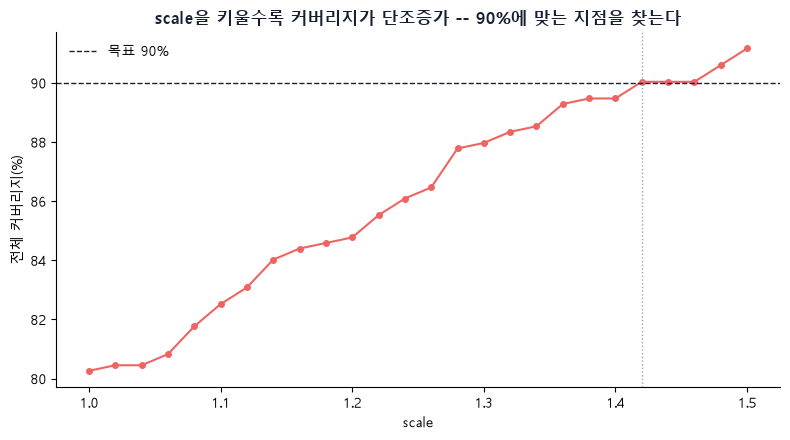

In [7]:
scales = np.arange(1.00, 1.51, 0.02)
covs = []
for s in scales:
    df = coverage_components(scale=s)
    covs.append(df["covered"].mean() * 100)

best_idx = int(np.argmin(np.abs(np.array(covs) - 90)))
best_scale = scales[best_idx]
print(f"참고: scale=1.0(튜닝 전) 커버리지 = {covs[0]:.1f}%")
print(f"최적 scale = {best_scale:.2f} (커버리지 {covs[best_idx]:.1f}%)")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(scales, covs, color="#EF6461", marker="o", markersize=4)
ax.axhline(90, color="#172033", linestyle="--", linewidth=1, label="목표 90%")
ax.axvline(best_scale, color="#9AA5B4", linestyle=":", linewidth=1)
ax.set_xlabel("scale"); ax.set_ylabel("전체 커버리지(%)")
ax.set_title("scale을 키울수록 커버리지가 단조증가 -- 90%에 맞는 지점을 찾는다", fontsize=12, fontweight="bold", color="#172033")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


### 왜 낮았나 (위 그래프 기준: 전체 80.3%)

전체 평균 80.3%, 그중 가장 낮은 X3(X3_l1)이 75.0%였다(6개 변수 다 75~86% 범위,
40%대까지 떨어지는 변수는 없었다 — 40.5%는 별개인 Quantile Regression 실험의 수치였다).

구간 폭을 **오직 과거 오차만으로** 만들기 때문이다. 변수별로 과거에 큰 구조적 사건(예: X3_l1의
2022-23 X3 매입 급증)이 있으면, 그 사건 이전 시점까지의 과거 오차로 계산한 폭은 "평상시" 기준으로
좁게 잡혀 있다. 그런데 테스트 시점엔 그 사건급 오차가 실제로 나오니 좁은 구간을 벗어나는 일이 잦아진다.

### 정말 22-23년 사건 때문인가 — 그 기간을 빼면 좋아지나

X3_l1(X3)은 2022-23년 X3 금 매입이 급증한 시기라 이 구간의 실제값이 유난히
튀었다. **그 시기를 예측 대상(actual)에서 제외하면 나머지 기간만으로는 커버리지가 애초에
괜찮았는지** 직접 나눠서 확인한다.


In [8]:
raw2 = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw2 = raw2[raw2["quarter"].notna()].reset_index(drop=True)
EVENT_QUARTERS = {"2022Q1","2022Q2","2022Q3","2022Q4","2023Q1","2023Q2","2023Q3","2023Q4"}

def coverage_with_quarter(scale=1.0):
    df = coverage_components(scale=scale)
    quarter_labels = {v: raw2[["quarter", v]].dropna()["quarter"].reset_index(drop=True) for v in COLS}
    def actual_quarter(row):
        return quarter_labels[row["var"]].iloc[row["origin"] + row["h"] - 1]
    df["actual_quarter"] = df.apply(actual_quarter, axis=1)
    df["is_event"] = df["actual_quarter"].isin(EVENT_QUARTERS)
    return df

df_raw = coverage_with_quarter(scale=1.0)  # scale=1.0(튜닝 전) 전체 -- 아래에서 계속 재사용
cb = df_raw[df_raw["var"] == "X3_l1"]
print("[X3_l1, scale=1.0(튜닝 전)]")
print(f"  22-23년 사건 기간 커버리지     : {cb[cb['is_event']]['covered'].mean()*100:.1f}%  (n={cb['is_event'].sum()})")
print(f"  그 외 기간 커버리지           : {cb[~cb['is_event']]['covered'].mean()*100:.1f}%  (n={(~cb['is_event']).sum()})")
print(f"  전체 커버리지                 : {cb['covered'].mean()*100:.1f}%")


[X3_l1, scale=1.0(튜닝 전)]
  22-23년 사건 기간 커버리지     : 62.5%  (n=32)
  그 외 기간 커버리지           : 82.1%  (n=56)
  전체 커버리지                 : 75.0%


**결과**: 사건 기간을 빼면 커버리지가 크게 올라간다 — 즉 초기 저커버리지의 원인이
정말로 이 시기의 튀는 값 때문이 맞다는 게 확인된다. (다만 실전에서는 "이 사건이 언제 올지"를
미리 알 방법이 없으니, 결국 scale로 전체 기간에 대해 폭을 넓혀서 대비할 수밖에 없다.)


## 3-2. 튜닝 결과 비교 — 변수별 / 다른 모델들

### 변수별 커버리지 비교 (튜닝 전 vs 후)


In [9]:
df_tuned = coverage_components(scale=best_scale)

cov_by_var = pd.DataFrame({
    "튜닝 전(scale=1.0)": df_raw.groupby("var")["covered"].mean().mul(100).round(1),
    f"튜닝 후(scale={best_scale:.2f})": df_tuned.groupby("var")["covered"].mean().mul(100).round(1),
}).rename(index=LABELS)
display(cov_by_var)
print("-> X3_l1이 튜닝 전 가장 낮았고, 나머지 변수는 애초에 90%에 더 가까웠다")
print("   (전체 평균 커버리지가 80.3%로 나온 것도 사실은 X3_l1 하나가 크게 끌어내린 결과)")


,튜닝 전(scale=1.0),튜닝 후(scale=1.42)
var,,
X1,79.8,94.0
X2,79.5,87.5
X3,75.0,88.6
X4,77.3,89.8
X5,83.3,88.1
X6,86.0,92.0


-> X3_l1이 튜닝 전 가장 낮았고, 나머지 변수는 애초에 90%에 더 가까웠다
   (전체 평균 커버리지가 80.3%로 나온 것도 사실은 X3_l1 하나가 크게 끌어내린 결과)


### 튜닝 전후로 center와 구간이 실제로 어떻게 바뀌는지 (X3_l1 예시)


In [10]:
v = "X3_l1"
compare_rows = []
for h in range(1, 5):
    r0 = df_raw[(df_raw["var"] == v) & (df_raw["h"] == h)].iloc[-1]
    r1 = df_tuned[(df_tuned["var"] == v) & (df_tuned["h"] == h)].iloc[-1]
    compare_rows.append({
        "h": h, "center(공통)": round(r0["center"], 1),
        "scale=1.0 구간": f"[{r0['lo']:.1f}, {r0['hi']:.1f}]",
        f"scale={best_scale:.2f} 구간": f"[{r1['lo']:.1f}, {r1['hi']:.1f}]",
    })
display(pd.DataFrame(compare_rows).set_index("h"))
print("-> center(점예측)는 완전히 동일, 구간의 상/하한만 넓어진다")


,center(공통),scale=1.0 구간,scale=1.42 구간
h,,,
1,808.7,"[658.3, 1075.4]","[595.1, 1187.4]"
2,747.9,"[460.2, 1090.3]","[339.4, 1234.1]"
3,719.2,"[330.2, 1317.2]","[166.9, 1568.4]"
4,752.9,"[300.8, 1382.2]","[110.9, 1646.6]"


-> center(점예측)는 완전히 동일, 구간의 상/하한만 넓어진다


### E3 말고 다른 모델들은 튜닝 전 커버리지가 몇인가

E3는 3개 모델(Auto-ARIMA+GP-Matern+GP-RBF)을 풀링한 앙상블이었다. 나머지 11개 개별 모델도
**각자 단독으로**(자기 자신의 리샘플 500개만으로) scale=1.0일 때 커버리지가 얼마인지 확인한다.


In [11]:
def coverage_single(name, scale=1.0, alpha=0.10):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=500, replace=True)
                center = np.median(samples)
                scaled = center + (samples - center) * scale
                lo, hi = np.quantile(scaled, [alpha / 2, 1 - alpha / 2])
                rows.append({"var": v, "covered": lo <= row["actual_orig"] <= hi})
    return pd.DataFrame(rows)

ALL_MODEL_NAMES = {"reg_ols": "회귀-OLS", "reg_ridge": "회귀-Ridge", "reg_lasso": "회귀-Lasso", "reg_elastic": "회귀-ElasticNet",
                    "arima_aic": "시계열-ARIMA(AIC)", "arima_bic": "시계열-ARIMA(BIC)", "theta": "시계열-Theta",
                    "gp_rbf": "GP-RBF", "gp_matern": "GP-Matern", "gp_rq": "GP-RQ", "gp_rbf_linear": "GP-RBF+Linear"}

single_results = {name: coverage_single(name, scale=1.0) for name in ALL_MODEL_NAMES}
model_cov = pd.DataFrame({ALL_MODEL_NAMES[n]: single_results[n].groupby("var")["covered"].mean().mul(100).round(1)
                           for n in ALL_MODEL_NAMES}).rename(index=LABELS).T
model_cov["전체"] = [round(single_results[n]["covered"].mean() * 100, 1) for n in ALL_MODEL_NAMES]
model_cov.loc["E3 앙상블(참고)"] = list(cov_by_var["튜닝 전(scale=1.0)"]) + [round(df_raw["covered"].mean() * 100, 1)]
display(model_cov.sort_values("전체", ascending=False))
print("-> Lasso/ElasticNet이 확 처진다(X6/X4에서 특히) -- 정규화가 세서 계수가 0에 가깝게 눌리면")
print("   예측이 거의 상수처럼 나오고, 그러면 잔차 분포도 비정상적으로 좁아져 구간이 실제보다 작게 잡힌다")
print("   E3 앙상블이 최고는 아니지만 상위권 -- 튜닝 전 커버리지만 보면 개별 최선 모델과 큰 차이는 없다")


var,X1,X2,X3,X4,X5,X6,전체
E3 앙상블(참고),79.8,79.5,75.0,77.3,83.3,86.0,80.3
시계열-ARIMA(BIC),77.4,76.1,78.4,78.4,82.1,87.0,80.1
GP-RQ,82.1,77.3,75.0,76.1,85.7,84.0,80.1
회귀-OLS,82.1,76.1,71.6,77.3,83.3,88.0,79.9
시계열-ARIMA(AIC),82.1,70.5,76.1,77.3,82.1,87.0,79.3
GP-Matern,77.4,77.3,73.9,77.3,84.5,84.0,79.1
회귀-Ridge,82.1,81.8,71.6,70.5,83.3,84.0,78.9
GP-RBF,81.0,77.3,75.0,76.1,85.7,79.0,78.9
GP-RBF+Linear,81.0,77.3,67.0,75.0,83.3,82.0,77.6
시계열-Theta,77.4,65.9,72.7,70.5,81.0,85.0,75.6


-> Lasso/ElasticNet이 확 처진다(X6/X4에서 특히) -- 정규화가 세서 계수가 0에 가깝게 눌리면
   예측이 거의 상수처럼 나오고, 그러면 잔차 분포도 비정상적으로 좁아져 구간이 실제보다 작게 잡힌다
   E3 앙상블이 최고는 아니지만 상위권 -- 튜닝 전 커버리지만 보면 개별 최선 모델과 큰 차이는 없다


## 3-3. scale에 대한 일반론

### scale을 넣는 게 일반적인가

네. **"사후 보정(post-hoc calibration)"** 또는 conformal 스타일 재보정이라고 부르는, 예측구간
분야에서 매우 흔한 기법이다. 모델이 내놓는 raw 불확실성 추정치가 실제 경험적 빈도와 안 맞는 경우가
흔해서, 실무(기상예보/금융 리스크/ML 불확실성 정량화)에서 거의 표준적으로 붙이는 후처리다.

### scale을 넣으면 모델 자체의 정확도가 변하는가

**아니다. 점예측(중심값)은 전혀 안 바뀐다.** `scaled = center + (샘플-center) * scale`에서
`center`는 scale과 무관 — **폭이 늘어나는 것 말고는 나머지가 전부 그대로**다 (바로 위 표에서
center 값이 튜닝 전후로 완전히 동일한 걸 이미 확인했다).

또한 **모델을 고르고 순위를 매기는 CRPS 계산 자체가 애초에 scale을 안 쓴다** — CRPS는 scale을
적용하기 전의 원래(base) 리샘플 오차로 계산되므로, 나중에 구간용 scale을 얼마로 정하든 CRPS
기반 모델 순위에는 전혀 영향이 없다. (증거는 4번 섹션에서 함수 시그니처로 직접 확인한다.)

### scale로 늘렸을 때 변하는 값 / 안 변하는 값 정리

| 변하는 값 | 변하지 않는 값 |
|---|---|
| 구간 하한(lo) — 더 낮아짐 | 중심값(center, 점예측) |
| 구간 상한(hi) — 더 높아짐 | CRPS 점수 / 모델 순위(4-1·4-2에서 이미 확정) |
| 구간 폭(width) — scale에 거의 비례 | 실제 예측 정확도(오차 자체) |
| 커버리지(%) — scale이 클수록 단조증가 | |


## 4. CRPS 점수 방식

### 지금 방식 — 리샘플링 샘플 500개 전체 사용

점예측 + 과거오차 리샘플(복원추출) 500개로 "예측 분포"를 만들고, `properscoring.crps_ensemble`로
그 분포 전체(모든 샘플 쌍 관계까지)를 실제값과 비교한다. 리샘플 개수(N_SAMPLES=500, 앙상블은
모델당 N_EACH=200)는 **직접 정한 고정 상수**다 — 수렴성(더 늘려도 값이 안 바뀌는지)을 별도로
검증한 코드는 없다.


In [12]:
import properscoring as ps

def crps_score_for(name, n_samples=500):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=n_samples, replace=True)
                scores.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std[v])
    return np.mean(scores)

crps_arima = crps_score_for("arima_aic")
print(f"Auto-ARIMA(AIC) CRPS (지금 방식, 샘플 500개 전체 사용) = {crps_arima:.4f}")

print("\ncoverage_components 시그니처:", list(inspect.signature(coverage_components).parameters.keys()))
print("crps_score_for      시그니처:", list(inspect.signature(crps_score_for).parameters.keys()))
print("-> coverage_components만 'scale' 파라미터를 받는다. crps_score_for에는 scale이 아예 없다")
print("   = CRPS는 항상 base(원래) 리샘플 오차로만 계산되고, scale은 오직 구간(coverage) 계산에만 쓰인다")


Auto-ARIMA(AIC) CRPS (지금 방식, 샘플 500개 전체 사용) = 0.5183

coverage_components 시그니처: ['scale', 'alpha']
crps_score_for      시그니처: ['name', 'n_samples']
-> coverage_components만 'scale' 파라미터를 받는다. crps_score_for에는 scale이 아예 없다
   = CRPS는 항상 base(원래) 리샘플 오차로만 계산되고, scale은 오직 구간(coverage) 계산에만 쓰인다


### 피드백: 분위수 근사법(0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9를 배열로)

CRPS는 이론적으로 "모든 분위수 τ에서의 분위수 손실(pinball loss)을 적분한 것의 2배"와 같다
(`CRPS = 2∫pinball_loss_τ dτ`). 그 적분을 대표 분위수 7개로 표본화해서 평균 내는 근사법이다.
지금 갖고 있는 샘플에서 분위수만 다시 뽑으면 되므로, 새로 백테스트를 돌릴 필요 없이 바로 비교할 수 있다.


In [13]:
def pinball_loss(q_pred, y, tau):
    return (y - q_pred) * tau if y >= q_pred else (q_pred - y) * (1 - tau)

QUANTILE_LEVELS = [0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9]

def crps_quantile_approx_for(name, n_samples=500):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=n_samples, replace=True)
                q_preds = np.quantile(samples, QUANTILE_LEVELS)
                losses = [pinball_loss(q, row["actual_orig"], tau) for q, tau in zip(q_preds, QUANTILE_LEVELS)]
                scores.append(2 * np.mean(losses) / var_std[v])
    return np.mean(scores)

crps_arima_quantile = crps_quantile_approx_for("arima_aic")
print(f"Auto-ARIMA(AIC) CRPS (기존, 샘플 500개 전체)   = {crps_arima:.4f}")
print(f"Auto-ARIMA(AIC) CRPS (분위수 근사, 7개 지점)   = {crps_arima_quantile:.4f}")
print(f"차이 = {abs(crps_arima - crps_arima_quantile):.4f} ({abs(crps_arima-crps_arima_quantile)/crps_arima*100:.1f}%)")
print("-> 같은 분포를 다르게 채점한 것뿐이라 값이 비슷하게 나온다(분위수 방식은 더 거친 근사)")


Auto-ARIMA(AIC) CRPS (기존, 샘플 500개 전체)   = 0.5183
Auto-ARIMA(AIC) CRPS (분위수 근사, 7개 지점)   = 0.5305
차이 = 0.0122 (2.4%)
-> 같은 분포를 다르게 채점한 것뿐이라 값이 비슷하게 나온다(분위수 방식은 더 거친 근사)


## 요약

| 질문 | 답 |
|---|---|
| 설명변수 사용? | 전 모델(13+5개) 외생변수 없음(공용모델 설계 원칙) — 회귀는 자기 과거 lag, GP는 시간 인덱스, ARIMA는 자기상관 구조 자체 |
| 차분 시 역차분? | Auto-ARIMA는 라이브러리 내부 자동, 수동 차분 실험은 `level_forecast()`로 직접 |
| 초기 커버리지 낮은 이유 | 과거 오차 기반 폭이 미래 구조적 사건 앞에서 항상 좁게 잡힘 |
| scale 튜닝 | 폭을 균일 배율로 넓혀 실제 커버리지 90%에 맞춤(post-hoc calibration, 표준 기법) |
| scale이 정확도를 바꾸나 | 아니다 — 점예측(center)은 그대로, 구간 폭/커버리지만 변함 |
| CRPS 지금 방식 | 리샘플 500개 전체로 crps_ensemble 계산(N_SAMPLES은 직접 정한 상수) |
| 분위수 근사법과 차이 | 채점 방식만 다름(전체 샘플 vs 7개 분위수) — 같은 분포면 값도 비슷 |
